# Predicción de compra de paquetes turísticos

## Objetivo
Saber qué clientes tienen más probabilidad de comprar un paquete (`ProdTaken = 1`) para enfocar sus llamadas de venta.

- **Problema:** clasificación binaria.
- **Objetivos (en datos de prueba):** Accuracy ≥ 85 %, ROC-AUC ≥ 0.85 y Recall de la clase "compra" ≥ 60 %.

## Datos

In [1]:
#%pip install statsmodels

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay, roc_curve
)
import plotly.express as px
import plotly.graph_objects as go

RS = 42
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

In [3]:
# Cargar datos
df = pd.read_csv('Travel_usar.csv')

# Funciones auxiliares de visualización y evaluación interactivas
def plot_distributions(df, columns, nbins=30):
    for col in columns:
        fig = px.histogram(
            df, x=col, nbins=nbins, marginal='box', opacity=0.7,
            title=f'Distribución de {col}'
        )
        fig.update_layout(bargap=0.2)
        fig.show()

def plot_tasa_por_categoria(df, columna, objetivo):
    tasa = df.groupby(columna, as_index=False)[objetivo].mean()
    fig = px.bar(
        tasa, x=columna, y=objetivo, text_auto='.1%',
        title=f'Tasa de {objetivo} por {columna}', template='plotly_white'
    )
    fig.update_layout(yaxis_tickformat='.0%', yaxis_title=f'Tasa de {objetivo}', width=700, height=450)
    fig.update_xaxes(type='category')
    fig.show()

def evaluar_clasificador(nombre, modelo, X_tr, y_tr, X_te, y_te):
    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)
    if hasattr(modelo, "predict_proba"):
        prob_te = modelo.predict_proba(X_te)[:, 1]
        auc_val = roc_auc_score(y_te, prob_te)
    else:
        auc_val = np.nan
    return {
        'Modelo': nombre,
        'Acc train': round(accuracy_score(y_tr, pred_tr), 3),
        'Acc test': round(accuracy_score(y_te, pred_te), 3),
        'Precision': round(precision_score(y_te, pred_te, zero_division=0), 3),
        'Recall': round(recall_score(y_te, pred_te, zero_division=0), 3),
        'F1': round(f1_score(y_te, pred_te, zero_division=0), 3),
        'AUC': round(auc_val, 3)
    }

def plot_matriz_confusion(y_true, y_pred, etiquetas=('No', 'Sí'), title='Matriz de confusión'):
    cm = pd.DataFrame(
        confusion_matrix(y_true, y_pred),
        index=[f'Real: {e}' for e in etiquetas],
        columns=[f'Predicho: {e}' for e in etiquetas]
    )
    fig = px.imshow(cm, text_auto=True, color_continuous_scale='Blues', title=title)
    fig.update_layout(width=650, height=450)
    fig.show()

def plot_curva_roc(y_true, y_proba, title='Curva ROC'):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auc = roc_auc_score(y_true, y_proba)
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=fpr, y=tpr, mode='lines', name=f'Modelo (AUC = {auc:.3f})',
        line=dict(color='steelblue', width=3)
    ))
    fig.add_trace(go.Scatter(
        x=[0, 1], y=[0, 1], mode='lines', name='Azar (AUC = 0.5)',
        line=dict(color='red', dash='dash')
    ))
    fig.update_layout(
        title=title, xaxis_title='Falsos positivos', yaxis_title='Verdaderos positivos (recall)',
        template='plotly_white', width=700, height=550
    )
    fig.show()

def plot_metricas_por_umbral(y_true, y_proba):
    umbrales = np.arange(0.05, 0.96, 0.05)
    filas = []
    for u in umbrales:
        y_pred = (y_proba >= u).astype(int)
        filas.append({
            'umbral': round(u, 2),
            'exactitud': accuracy_score(y_true, y_pred),
            'precisión': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'F1': f1_score(y_true, y_pred, zero_division=0),
        })
    datos = pd.DataFrame(filas).melt(id_vars='umbral', var_name='métrica', value_name='valor')
    fig = px.line(
        datos, x='umbral', y='valor', color='métrica', markers=True,
        title='Métricas según el umbral de decisión', template='plotly_white'
    )
    fig.add_vline(x=0.5, line_dash='dash', line_color='gray', annotation_text='umbral por defecto (0.5)')
    fig.update_layout(width=900, height=500)
    fig.show()

def plot_curva_complejidad(valores, score_train, score_test, parametro='max_depth', metrica='Exactitud'):
    datos = pd.DataFrame({
        parametro: list(valores) * 2,
        metrica: list(score_train) + list(score_test),
        'conjunto': ['Entrenamiento'] * len(score_train) + ['Prueba'] * len(score_test)
    })
    fig = px.line(
        datos, x=parametro, y=metrica, color='conjunto', markers=True,
        title=f'Diagnóstico de Sobreajuste: {metrica} según {parametro}',
        template='plotly_white', color_discrete_map={'Entrenamiento': 'steelblue', 'Prueba': 'tomato'}
    )
    fig.update_layout(width=900, height=450)
    fig.show()

def plot_importancias(modelo, columnas, top_n=None):
    imp = pd.Series(modelo.feature_importances_, index=columnas).sort_values(ascending=True)
    if top_n:
        imp = imp.tail(top_n)
    fig = px.bar(
        x=imp.values, y=imp.index, orientation='h', text_auto='.3f',
        labels={'x': 'Importancia (reducción de impureza Gini)', 'y': ''},
        title='Importancia de Variables en el Árbol', template='plotly_white'
    )
    fig.update_layout(width=800, height=450)
    fig.show()
    return imp.sort_values(ascending=False)

df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [4]:
# Tamaño, tipos y nulos
print(df.shape)
df.info()

(4888, 20)
<class 'pandas.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                4888 non-null   int64  
 1   ProdTaken                 4888 non-null   int64  
 2   Age                       4662 non-null   float64
 3   TypeofContact             4863 non-null   str    
 4   CityTier                  4888 non-null   int64  
 5   DurationOfPitch           4637 non-null   float64
 6   Occupation                4888 non-null   str    
 7   Gender                    4888 non-null   str    
 8   NumberOfPersonVisiting    4888 non-null   int64  
 9   NumberOfFollowups         4843 non-null   float64
 10  ProductPitched            4888 non-null   str    
 11  PreferredPropertyStar     4862 non-null   float64
 12  MaritalStatus             4888 non-null   str    
 13  NumberOfTrips             4748 non-null   float64
 14  Passport

In [5]:
# Estadística descriptiva de numéricas y categóricas
display(df.describe().T)
display(df.describe(include='object').T)

,count,mean,std,min,25%,50%,75%,max
CustomerID,4888.0,202443.500000,1411.188388,200000.0,201221.75,202443.5,203665.25,204887.0
ProdTaken,4888.0,0.188216,0.390925,0.0,0.00,0.0,0.00,1.0
Age,4662.0,37.622265,9.316387,18.0,31.00,36.0,44.00,61.0
CityTier,4888.0,1.654255,0.916583,1.0,1.00,1.0,3.00,3.0
DurationOfPitch,4637.0,15.490835,8.519643,5.0,9.00,13.0,20.00,127.0
NumberOfPersonVisiting,4888.0,2.905074,0.724891,1.0,2.00,3.0,3.00,5.0
NumberOfFollowups,4843.0,3.708445,1.002509,1.0,3.00,4.0,4.00,6.0
PreferredPropertyStar,4862.0,3.581037,0.798009,3.0,3.00,3.0,4.00,5.0
NumberOfTrips,4748.0,3.236521,1.849019,1.0,2.00,3.0,4.00,22.0
Passport,4888.0,0.290917,0.454232,0.0,0.00,0.0,1.00,1.0


/tmp/ipykernel_2011/2598732088.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object').T)


,count,unique,top,freq
TypeofContact,4863,2,Self Enquiry,3444
Occupation,4888,4,Salaried,2368
Gender,4888,3,Male,2916
ProductPitched,4888,5,Basic,1842
MaritalStatus,4888,4,Married,2340
Designation,4888,5,Executive,1842


In [6]:
# Valores de cada variable categórica
for c in df.select_dtypes(exclude='number'):
    print(df[c].value_counts(), '\n')

TypeofContact
Self Enquiry       3444
Company Invited    1419
Name: count, dtype: int64 

Occupation
Salaried          2368
Small Business    2084
Large Business     434
Free Lancer          2
Name: count, dtype: int64 

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64 

ProductPitched
Basic           1842
Deluxe          1732
Standard         742
Super Deluxe     342
King             230
Name: count, dtype: int64 

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64 

Designation
Executive         1842
Manager           1732
Senior Manager     742
AVP                342
VP                 230
Name: count, dtype: int64 



In [7]:
# Porcentaje de nulos y duplicados
print((df.isna().mean()*100).round(2)[df.isna().any()])
print('Duplicados:', df.duplicated().sum())

Age                         4.62
TypeofContact               0.51
DurationOfPitch             5.14
NumberOfFollowups           0.92
PreferredPropertyStar       0.53
NumberOfTrips               2.86
NumberOfChildrenVisiting    1.35
MonthlyIncome               4.77
dtype: float64
Duplicados: 0


ProdTaken
0    0.812
1    0.188
Name: proportion, dtype: float64


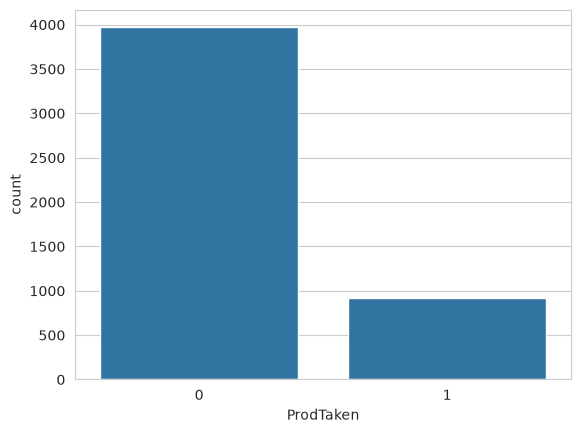

In [8]:
# Distribución de la variable objetivo
print(df['ProdTaken'].value_counts(normalize=True).round(3))
sns.countplot(data=df, x='ProdTaken')
plt.show()

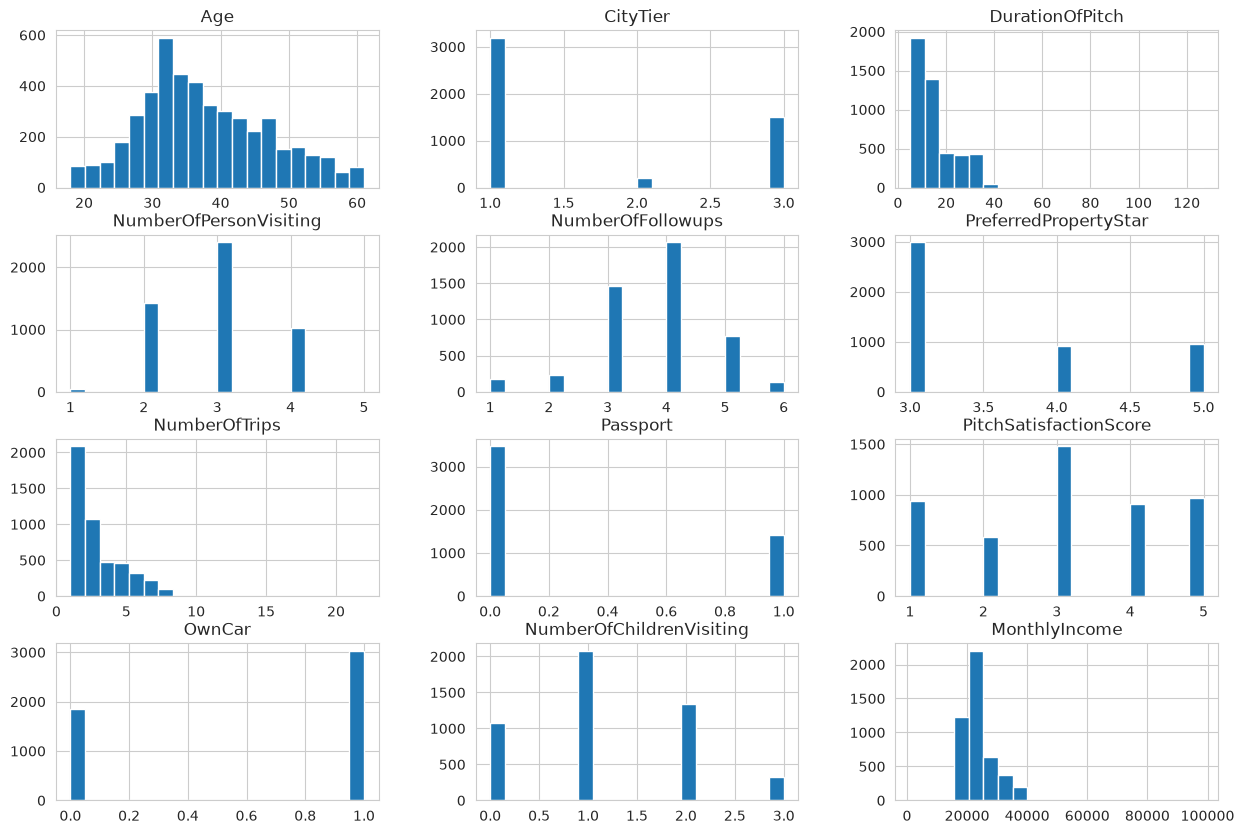

In [9]:
# Histogramas de las variables numéricas
df.drop(columns=['CustomerID','ProdTaken']).hist(bins=20, figsize=(15,10))
plt.show()

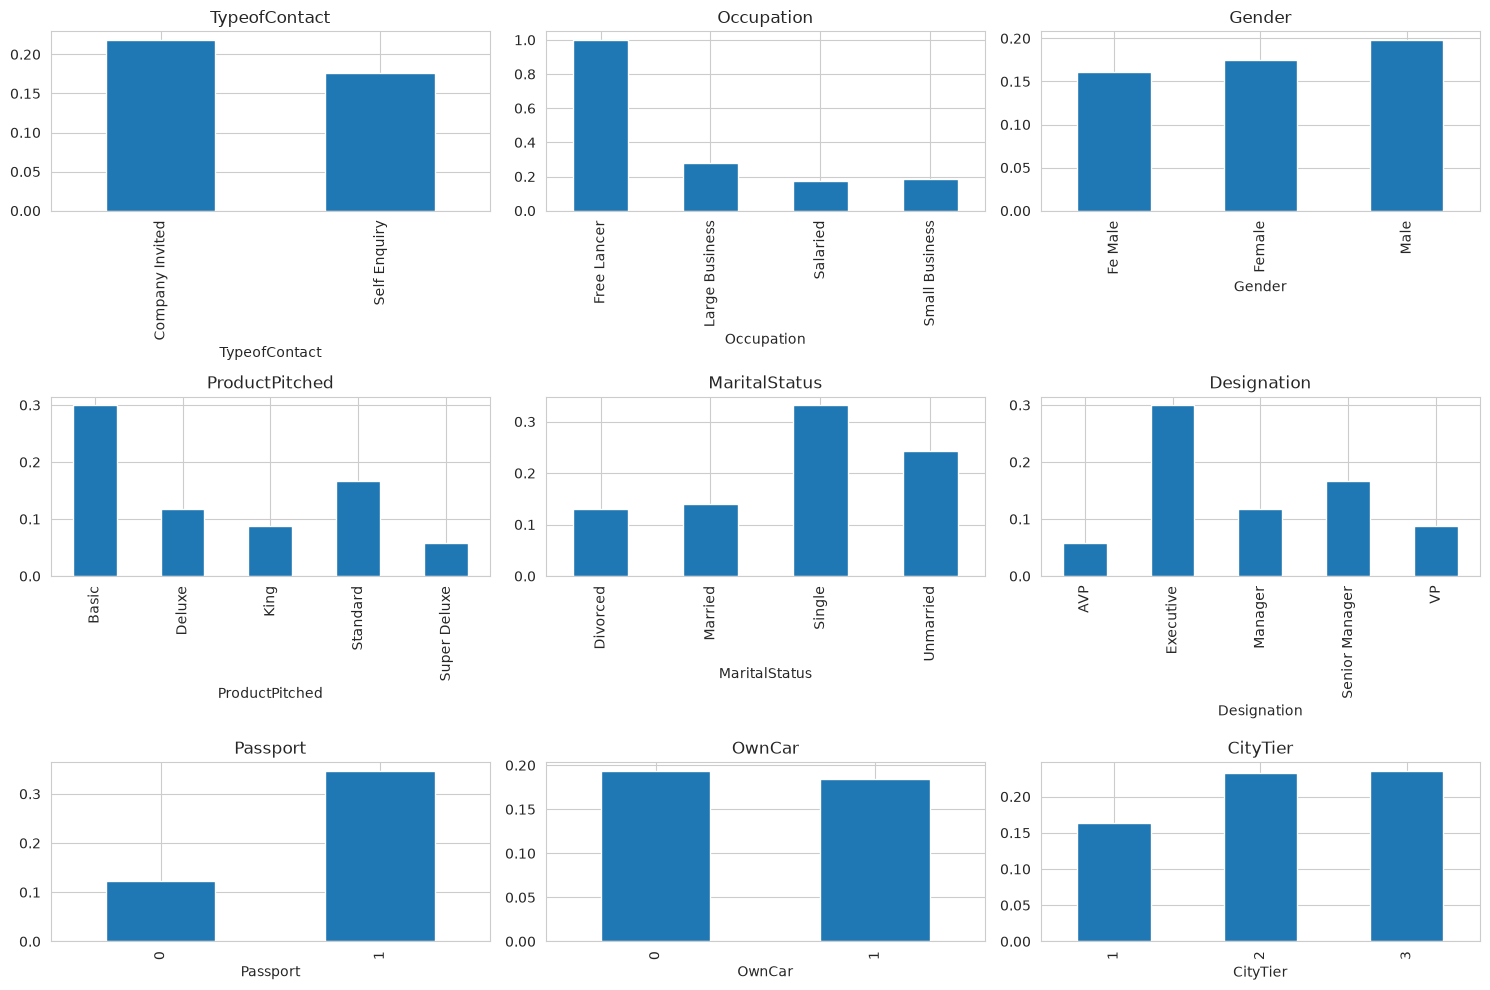

In [10]:
# Tasa de compra por cada variable categórica
cats = ['TypeofContact','Occupation','Gender','ProductPitched','MaritalStatus','Designation','Passport','OwnCar','CityTier']
fig, axes = plt.subplots(3, 3, figsize=(15,10))
for ax, c in zip(axes.ravel(), cats):
    df.groupby(c)['ProdTaken'].mean().plot.bar(ax=ax, title=c)
plt.tight_layout()
plt.show()

In [11]:
# ProductPitched contra Designation
pd.crosstab(df['ProductPitched'], df['Designation'])

Designation,AVP,Executive,Manager,Senior Manager,VP
ProductPitched,,,,,
Basic,0,1842,0,0,0
Deluxe,0,0,1732,0,0
King,0,0,0,0,230
Standard,0,0,0,742,0
Super Deluxe,342,0,0,0,0


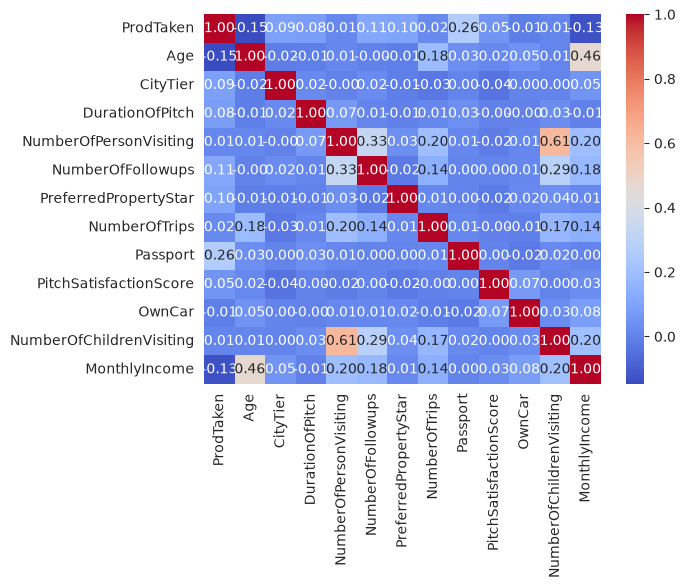

In [12]:
# Correlación entre numéricas
sns.heatmap(df.select_dtypes('number').drop(columns='CustomerID').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

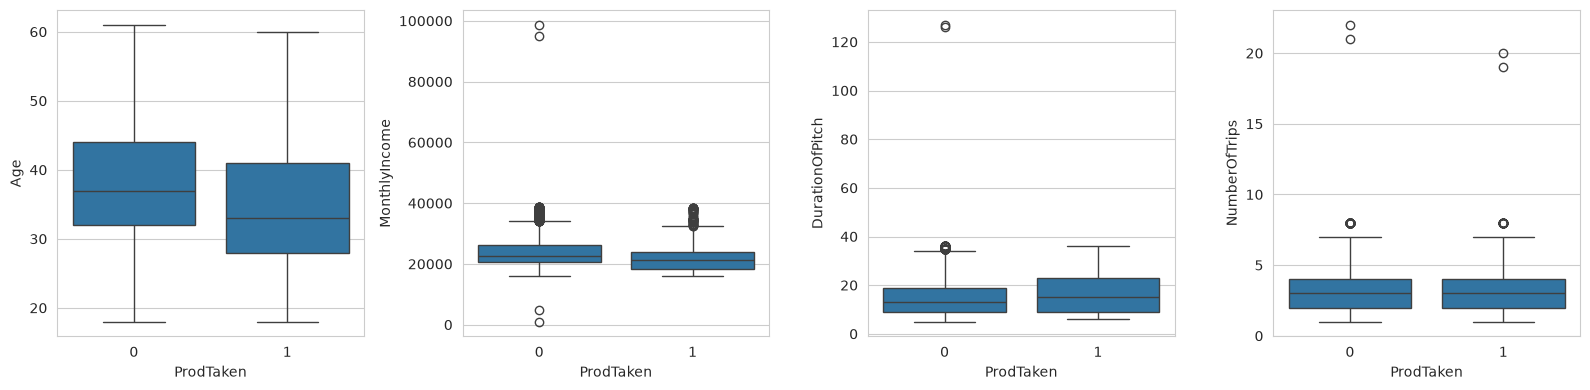

In [13]:
# Boxplots de las numéricas con más valores extremos contra el objetivo
fig, axes = plt.subplots(1, 4, figsize=(16,4))
for ax, c in zip(axes, ['Age','MonthlyIncome','DurationOfPitch','NumberOfTrips']):
    sns.boxplot(data=df, x='ProdTaken', y=c, ax=ax)
plt.tight_layout()
plt.show()

- Solo **18.8 %** de los clientes compró, hay desbalance de clases
- Hay nulos en 7 variables
- `Gender` tiene un error de captura (*Fe Male*) y `Occupation` tiene solo 2 casos de Free Lancer.
- `ProductPitched` y `Designation` son la misma información, entonces se elimina una.
- Compran más: clientes con pasaporte, solteros, más jóvenes, contactados por la empresa y a los que se les ofreció el paquete Basic.
- `MonthlyIncome`, `DurationOfPitch` y `NumberOfTrips` tienen valores extremos.

## Preparación de los datos

In [14]:
# Corregir Gender y quitar columnas que no aportan (ID y Designation, duplicada de ProductPitched)
data = df.copy()
data['Gender'] = data['Gender'].replace('Fe Male', 'Female')
data = data.drop(columns=['CustomerID','Designation'])

In [15]:
# Definir target y variables, separar train y test estratificado
X = data.drop(columns='ProdTaken')
y = data['ProdTaken']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print(X_train.shape, X_test.shape)

(3910, 17) (978, 17)


### Outliers

In [16]:
# Límites IQR calculados con train
cols_out = ['Age','DurationOfPitch','NumberOfTrips','MonthlyIncome']
limites = {}
for c in cols_out:
    q1, q3 = X_train[c].quantile([0.25, 0.75])
    limites[c] = (q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1))
    print(c, 'outliers:', ((X_train[c] < limites[c][0]) | (X_train[c] > limites[c][1])).sum())

Age outliers: 0
DurationOfPitch outliers: 2
NumberOfTrips outliers: 89
MonthlyIncome outliers: 265


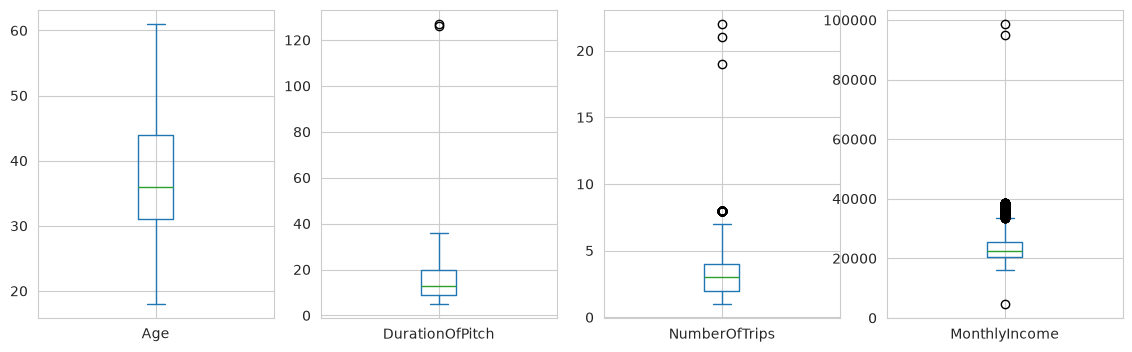

In [17]:
# Boxplots antes del recorte
X_train[cols_out].plot.box(subplots=True, layout=(1,4), figsize=(14,4))
plt.show()

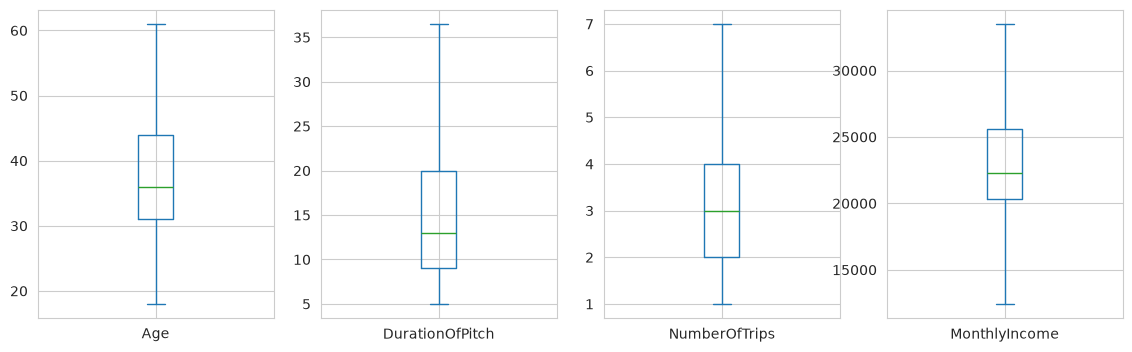

In [18]:
# Recortar outliers en train y test con los límites de train
for c in cols_out:
    X_train[c] = X_train[c].clip(*limites[c])
    X_test[c] = X_test[c].clip(*limites[c])
X_train[cols_out].plot.box(subplots=True, layout=(1,4), figsize=(14,4))
plt.show()

### Nulos (mediana para numéricas, moda para categóricas)

In [19]:
# Pipeline de Preprocesamiento robusto usando Pipelines y ColumnTransformers
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(include='object').columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Ajustar preprocesador en train y transformar ambos conjuntos
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = [n.split('__')[-1] for n in preprocessor.get_feature_names_out()]

X_train_df = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
X_test_df = pd.DataFrame(X_test_proc, columns=feature_names, index=X_test.index)

# Sobrescribir variables de compatibilidad hacia adelante
Xtr = X_train_df
Xte = X_test_df
print("Variables procesadas finales:", Xtr.shape[1])

Variables procesadas finales: 24


/tmp/ipykernel_2011/813432262.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include='object').columns.tolist()


### Codificación de categóricas

In [20]:
# Los datos ya han sido codificados y procesados mediante la Pipeline en la celda anterior.
# Mostramos las primeras filas de Xtr (conjunto procesado) para verificar la compatibilidad hacia adelante.
Xtr.head()

,Age,CityTier,DurationOfPitch,NumberOfPersonVisiting,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,MonthlyIncome,TypeofContact_Self Enquiry,Occupation_Large Business,Occupation_Salaried,Occupation_Small Business,Gender_Male,ProductPitched_Deluxe,ProductPitched_King,ProductPitched_Standard,ProductPitched_Super Deluxe,MaritalStatus_Married,MaritalStatus_Single,MaritalStatus_Unmarried
619,-0.173791,1.477328,-1.162238,-1.256729,-2.708464,1.775141,-0.700644,-0.64351,0.670552,-1.279276,-1.379190,-0.231218,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1227,-0.173791,-0.711099,-0.914326,0.128223,-0.708068,-0.729659,-0.700644,-0.64351,1.401078,-1.279276,0.964414,-1.055660,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3238,-0.283409,-0.711099,-0.666414,0.128223,0.292129,-0.729659,-0.700644,-0.64351,-0.790500,0.781692,-0.207388,0.662541,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3961,0.045445,-0.711099,1.316882,1.513175,0.292129,0.522741,1.641826,-0.64351,0.670552,-1.279276,0.964414,-0.359699,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
490,0.045445,-0.711099,-1.162238,-1.256729,-0.708068,1.775141,0.470591,-0.64351,-0.790500,0.781692,-0.207388,-1.240933,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### Alineación y Validación de Conjuntos Procesados
La pipeline robusta anterior ya imputó nulos de manera segura y escaló las variables numéricas. Usaremos `Xtr` y `Xte` como nuestros conjuntos limpios de producción.

In [21]:
# Celda redundante eliminada. Verificamos la consistencia de los datos limpios.
print("Valores nulos residuales en entrenamiento:", Xtr.isna().sum().sum())
print("Valores nulos residuales en prueba:", Xte.isna().sum().sum())
Xtr.describe().T[['mean','std']].head()

Valores nulos residuales en entrenamiento: 0
Valores nulos residuales en prueba: 0


,mean,std
Age,-1.453796e-17,1.000128
CityTier,8.722775e-17,1.000128
DurationOfPitch,5.996908e-17,1.000128
NumberOfPersonVisiting,-2.035314e-16,1.000128
NumberOfFollowups,-1.090347e-17,1.000128


### Selección de variables (feature importance)

In [22]:
# Importancia de variables con Árbol para feature selection
arbol_fi = DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=RS).fit(Xtr, y_train)
imp = pd.Series(arbol_fi.feature_importances_, index=Xtr.columns).sort_values(ascending=False)
plot_importancias(arbol_fi, Xtr.columns)

Passport                       1.715542e-01
DurationOfPitch                1.653815e-01
Age                            1.044222e-01
MonthlyIncome                  8.529093e-02
CityTier                       6.854564e-02
PitchSatisfactionScore         6.530242e-02
PreferredPropertyStar          4.810833e-02
ProductPitched_Deluxe          4.127785e-02
MaritalStatus_Unmarried        4.057157e-02
NumberOfTrips                  3.957062e-02
NumberOfFollowups              3.727408e-02
MaritalStatus_Single           3.151208e-02
Occupation_Large Business      2.205132e-02
Gender_Male                    2.182193e-02
OwnCar                         1.680816e-02
ProductPitched_Super Deluxe    1.409669e-02
NumberOfPersonVisiting         1.306876e-02
TypeofContact_Self Enquiry     8.084102e-03
Occupation_Small Business      3.578521e-03
ProductPitched_King            1.679071e-03
ProductPitched_Standard        2.507024e-17
Occupation_Salaried            1.450824e-18
MaritalStatus_Married          0

In [23]:
# Quedarnos con las variables que acumulan el 90 % de la importancia
sel = imp.index[:(imp.cumsum() < 0.90).sum() + 1].tolist()
top2 = imp.index[:2].tolist()
print(len(sel), sel)
print('Top 2:', top2)

13 ['Passport', 'DurationOfPitch', 'Age', 'MonthlyIncome', 'CityTier', 'PitchSatisfactionScore', 'PreferredPropertyStar', 'ProductPitched_Deluxe', 'MaritalStatus_Unmarried', 'NumberOfTrips', 'NumberOfFollowups', 'MaritalStatus_Single', 'Occupation_Large Business']
Top 2: ['Passport', 'DurationOfPitch']


**Resultado de la selección:** 13 variables acumulan el 90 % de la importancia (`Passport`, `DurationOfPitch`, `Age`, `MonthlyIncome`, `CityTier`, `PitchSatisfactionScore`, `PreferredPropertyStar`, `ProductPitched_Deluxe`, `MaritalStatus_Unmarried`, `NumberOfTrips`, `NumberOfFollowups`, `MaritalStatus_Single`, `Occupation_Large Business`). Las dos primeras (`Passport` y `DurationOfPitch`) se usan para graficar la región de decisión de los modelos.

# REGRESIÓN LOGÍSTICA

### Funciones auxiliares (usadas todos los modelos)

In [24]:
# Funciones auxiliares clásicas adaptadas para heredar los resultados de evaluación interactiva
def evaluar(nombre, modelo, cols):
    return evaluar_clasificador(nombre, modelo, Xtr[cols], y_train, Xte[cols], y_test)

def region(modelo, cols, titulo):
    a, b = Xtr[cols[0]], Xtr[cols[1]]
    xx, yy = np.meshgrid(np.linspace(a.min()-0.5, a.max()+0.5, 300), np.linspace(b.min()-0.5, b.max()+0.5, 300))
    # Convertir a DataFrame con nombres de columnas para evitar el UserWarning de scikit-learn
    grid_df = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=cols)
    Z = modelo.predict(grid_df).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlGn')
    plt.scatter(Xte[cols[0]], Xte[cols[1]], c=y_test, cmap='RdYlGn', edgecolor='k')
    plt.xlabel(cols[0]); plt.ylabel(cols[1]); plt.title(titulo)
    plt.show()

def reporte(modelo, cols):
    pred = modelo.predict(Xte[cols])
    print(classification_report(y_test, pred, target_names=['No compra','Compra']))
    plot_matriz_confusion(y_test, pred, etiquetas=('No', 'Sí'), title=f'Matriz de Confusión - {type(modelo).__name__}')
    if hasattr(modelo, "predict_proba"):
        plot_curva_roc(y_test, modelo.predict_proba(Xte[cols])[:, 1])

res = []

### Regresión logística con las 2 mejores variables

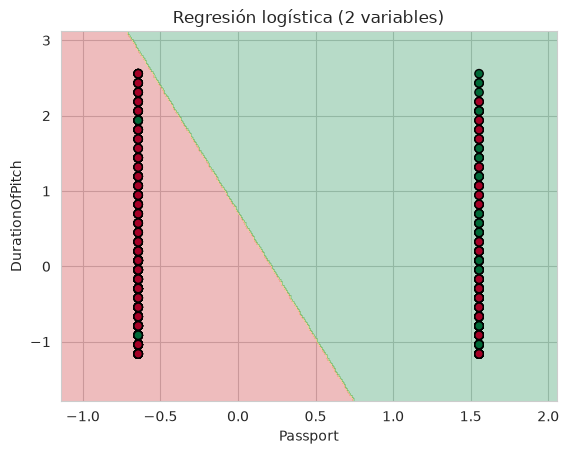

,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652


In [25]:
# Regresión logística con las 2 mejores variables (los datos ya no contienen NaNs residuales gracias al ColumnTransformer)
log2 = LogisticRegression(class_weight='balanced', max_iter=1000).fit(Xtr[top2], y_train)
region(log2, top2, 'Regresión logística (2 variables)')
res.append(evaluar('Logística 2 variables', log2, top2))
pd.DataFrame(res).round(3)

###  StatsModels: coeficientes, p-values y odds ratios

In [26]:
# StatsModels con las variables seleccionadas
logit = sm.Logit(y_train, sm.add_constant(Xtr[sel])).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:              ProdTaken   No. Observations:                 3910
Model:                          Logit   Df Residuals:                     3896
Method:                           MLE   Df Model:                           13
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.2294
Time:                        19:21:27   Log-Likelihood:                -1457.3
converged:                       True   LL-Null:                       -1891.1
Covariance Type:            nonrobust   LLR p-value:                4.681e-177
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                        -1.9169      0.075    -25.431      0.000      -2.065      -1.769
Passport                      0.7345      0.045     16.482      0.000       0.647     

In [27]:
# Odds ratios y significancia
tabla = pd.DataFrame({'coef': logit.params, 'odds_ratio': np.exp(logit.params), 'p_value': logit.pvalues}).drop('const')
tabla.sort_values('p_value').round(4)

,coef,odds_ratio,p_value
Passport,0.7345,2.0844,0.0000
MaritalStatus_Single,1.1383,3.1214,0.0000
ProductPitched_Deluxe,-1.1242,0.3249,0.0000
CityTier,0.4663,1.5941,0.0000
NumberOfFollowups,0.4423,1.5563,0.0000
MonthlyIncome,-0.5147,0.5977,0.0000
PreferredPropertyStar,0.3170,1.3731,0.0000
DurationOfPitch,0.2962,1.3448,0.0000
MaritalStatus_Unmarried,0.7602,2.1387,0.0000
Occupation_Large Business,0.5249,1.6902,0.0004


In [28]:
# Quedarnos con las variables significativas (p < 0.05)
sel_log = tabla[tabla['p_value'] < 0.05].index.tolist()
print(len(sel_log), sel_log)

13 ['Passport', 'DurationOfPitch', 'Age', 'MonthlyIncome', 'CityTier', 'PitchSatisfactionScore', 'PreferredPropertyStar', 'ProductPitched_Deluxe', 'MaritalStatus_Unmarried', 'NumberOfTrips', 'NumberOfFollowups', 'MaritalStatus_Single', 'Occupation_Large Business']


### Regresión logística final

In [29]:
# Ajustar C con validación cruzada (métrica F1)
gs_log = GridSearchCV(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RS),
                      {'C': [0.01, 0.1, 1, 10, 100]}, scoring='f1', cv=5).fit(Xtr[sel_log], y_train)
log_final = gs_log.best_estimator_
print(gs_log.best_params_, round(gs_log.best_score_, 3))
res.append(evaluar('Regresión logística', log_final, sel_log))

# Evaluar curvas por umbral del modelo final
proba_log_test = log_final.predict_proba(Xte[sel_log])[:, 1]
plot_metricas_por_umbral(y_test, proba_log_test)
pd.DataFrame(res).round(3)

{'C': 1} 0.518


,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
1,Regresión logística,0.744,0.712,0.357,0.663,0.464,0.764


### Evaluación de la regresión logística

In [30]:
# Reporte, matriz de confusión y curva ROC
reporte(log_final, sel_log)

              precision    recall  f1-score   support

   No compra       0.90      0.72      0.80       794
      Compra       0.36      0.66      0.46       184

    accuracy                           0.71       978
   macro avg       0.63      0.69      0.63       978
weighted avg       0.80      0.71      0.74       978



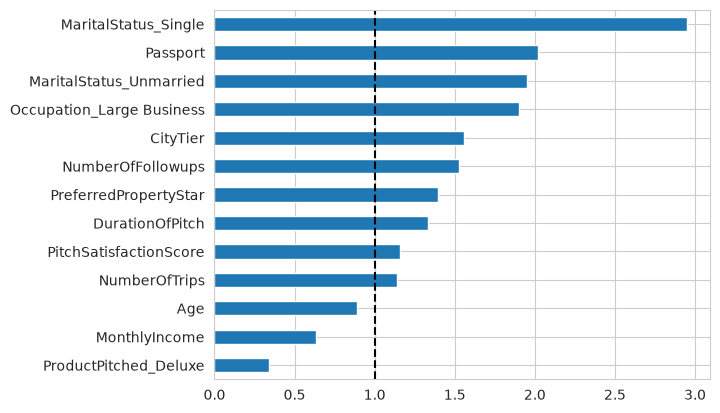

In [31]:
# Odds ratios del modelo final (>1 aumenta la probabilidad de compra, <1 la disminuye)
pd.Series(np.exp(log_final.coef_[0]), index=sel_log).sort_values().plot.barh()
plt.axvline(1, color='k', linestyle='--')
plt.show()

# MODELO 2: ÁRBOL DE DECISIÓN PODADO

### Árbol con 2 variables

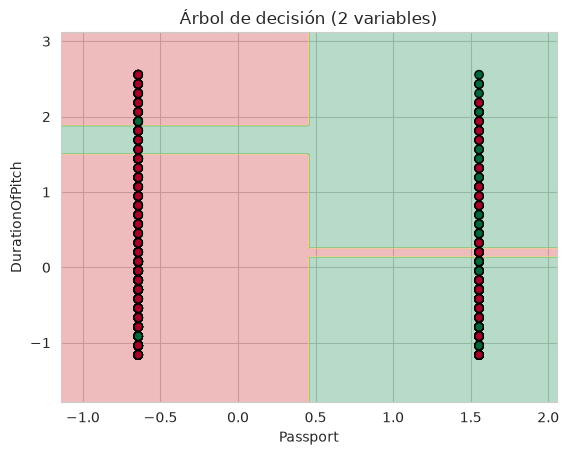

,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
1,Regresión logística,0.744,0.712,0.357,0.663,0.464,0.764
2,Árbol 2 variables,0.714,0.702,0.315,0.495,0.385,0.649


In [32]:
# Árbol con las 2 mejores variables
arbol2 = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RS).fit(Xtr[top2], y_train)
region(arbol2, top2, 'Árbol de decisión (2 variables)')
res.append(evaluar('Árbol 2 variables', arbol2, top2))
pd.DataFrame(res).round(3)

### Poda del árbol

In [33]:
# Curva de Complejidad interactiva para diagnosticar sobreajuste
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15]
acc_tr, acc_te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=RS).fit(Xtr[sel], y_train)
    acc_tr.append(m.score(Xtr[sel], y_train))
    acc_te.append(m.score(Xte[sel], y_test))

plot_curva_complejidad(depths, acc_tr, acc_te, parametro='max_depth', metrica='Exactitud')

In [34]:
# Buscar mejores hiperparámetros de poda con validación cruzada (métrica F1)
params = {'max_depth': [3, 4, 5, 6, 8, 10, 12],
          'min_samples_leaf': [1, 5, 10, 20],
          'ccp_alpha': [0, 0.0005, 0.001, 0.002, 0.005]}
gs = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=RS), params,
                  scoring='f1', cv=5, n_jobs=-1).fit(Xtr[sel], y_train)
print(gs.best_params_, round(gs.best_score_, 3))
arbol_podado = gs.best_estimator_
print('Profundidad:', arbol_podado.get_depth(), '| Hojas:', arbol_podado.get_n_leaves())
res.append(evaluar('Árbol podado', arbol_podado, sel))
pd.DataFrame(res).round(3)

{'ccp_alpha': 0, 'max_depth': 12, 'min_samples_leaf': 1} 0.638
Profundidad: 12 | Hojas: 413


,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
1,Regresión logística,0.744,0.712,0.357,0.663,0.464,0.764
2,Árbol 2 variables,0.714,0.702,0.315,0.495,0.385,0.649
3,Árbol podado,0.956,0.852,0.587,0.717,0.645,0.815


### Evaluación e interpretación del árbol podado

In [35]:
# Reporte, matriz de confusión y curva ROC
reporte(arbol_podado, sel)

              precision    recall  f1-score   support

   No compra       0.93      0.88      0.91       794
      Compra       0.59      0.72      0.65       184

    accuracy                           0.85       978
   macro avg       0.76      0.80      0.78       978
weighted avg       0.87      0.85      0.86       978



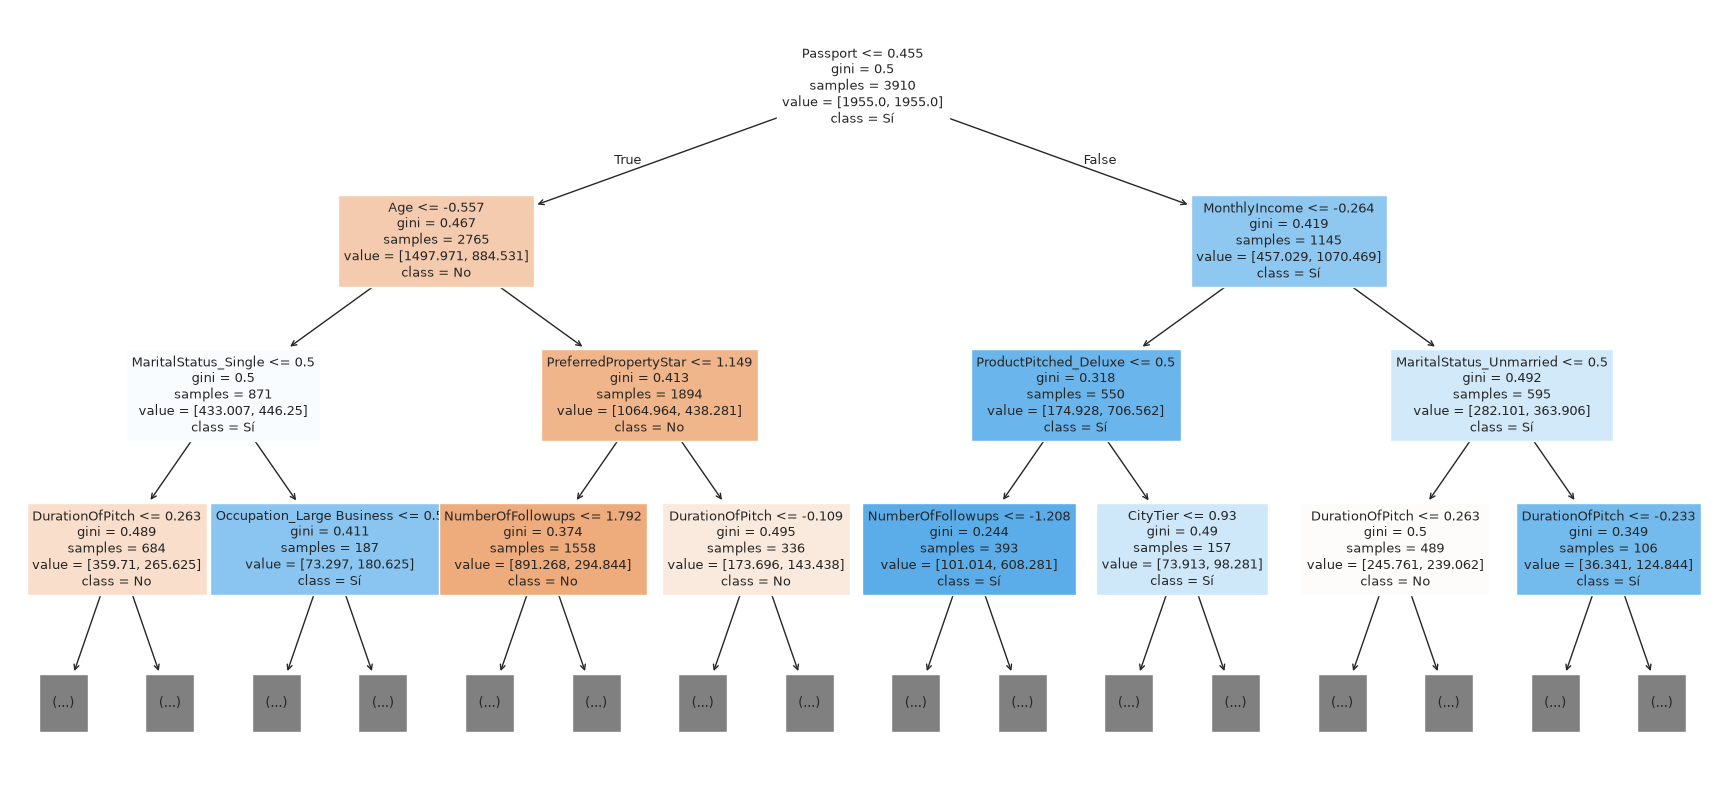

In [36]:
# Dibujar el árbol podado (primeros niveles)
plt.figure(figsize=(22,10))
plot_tree(arbol_podado, feature_names=sel, class_names=['No','Sí'], filled=True, max_depth=3, fontsize=9)
plt.show()

In [37]:
# Reglas del árbol podado (primeros niveles)
print(export_text(arbol_podado, feature_names=sel, max_depth=3))

|--- Passport <= 0.46
|   |--- Age <= -0.56
|   |   |--- MaritalStatus_Single <= 0.50
|   |   |   |--- DurationOfPitch <= 0.26
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- DurationOfPitch >  0.26
|   |   |   |   |--- truncated branch of depth 9
|   |   |--- MaritalStatus_Single >  0.50
|   |   |   |--- Occupation_Large Business <= 0.50
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- Occupation_Large Business >  0.50
|   |   |   |   |--- truncated branch of depth 6
|   |--- Age >  -0.56
|   |   |--- PreferredPropertyStar <= 1.15
|   |   |   |--- NumberOfFollowups <= 1.79
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- NumberOfFollowups >  1.79
|   |   |   |   |--- truncated branch of depth 8
|   |   |--- PreferredPropertyStar >  1.15
|   |   |   |--- DurationOfPitch <= -0.11
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- DurationOfPitch >  -0.11
|   |   |   |   |--- truncated branch of depth 9
|--- Passport >  0

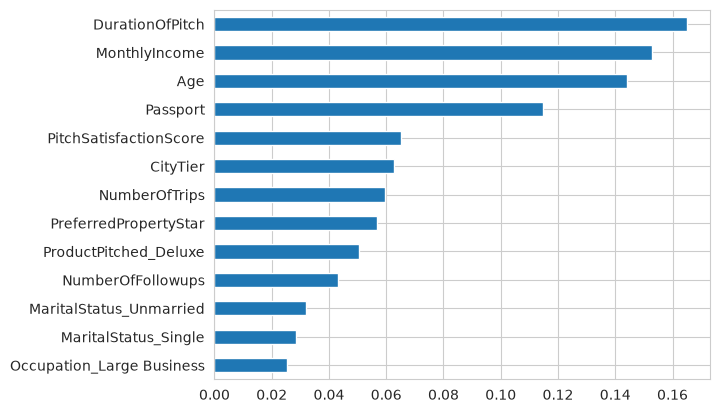

In [38]:
# Importancia de variables del árbol podado
pd.Series(arbol_podado.feature_importances_, index=sel).sort_values().plot.barh()
plt.show()

# MODELO 3: ÁRBOL DE DECISIÓN SIN PODAR

In [39]:
# Árbol sin límite de profundidad
arbol_full = DecisionTreeClassifier(class_weight='balanced', random_state=RS).fit(Xtr[sel], y_train)
print('Profundidad:', arbol_full.get_depth(), '| Hojas:', arbol_full.get_n_leaves())
res.append(evaluar('Árbol sin podar', arbol_full, sel))
pd.DataFrame(res).round(3)

Profundidad: 18 | Hojas: 548


,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
1,Regresión logística,0.744,0.712,0.357,0.663,0.464,0.764
2,Árbol 2 variables,0.714,0.702,0.315,0.495,0.385,0.649
3,Árbol podado,0.956,0.852,0.587,0.717,0.645,0.815
4,Árbol sin podar,1.000,0.895,0.740,0.679,0.708,0.812


In [40]:
# Reporte, matriz de confusión y curva ROC
reporte(arbol_full, sel)

              precision    recall  f1-score   support

   No compra       0.93      0.94      0.94       794
      Compra       0.74      0.68      0.71       184

    accuracy                           0.89       978
   macro avg       0.83      0.81      0.82       978
weighted avg       0.89      0.89      0.89       978



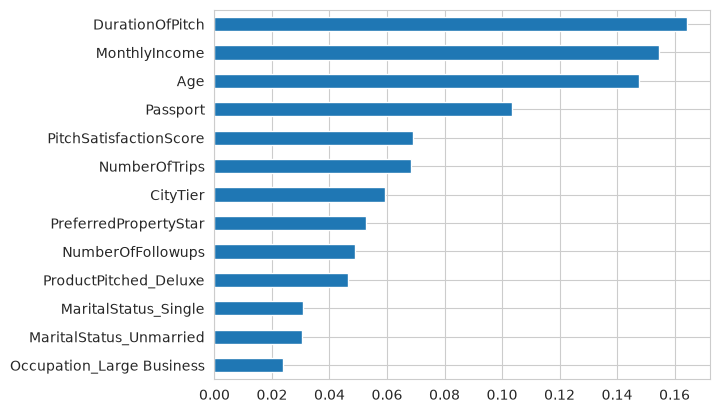

In [41]:
# Importancia de variables del árbol sin podar
pd.Series(arbol_full.feature_importances_, index=sel).sort_values().plot.barh()
plt.show()

**Resultados del árbol sin podar (datos de prueba)**

| Modelo | Acc train | Acc test | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Árbol sin podar (18 niveles, 548 hojas) | 1.000 | 0.888 | 0.658 | 0.688 | 0.799 |

- Memoriza el entrenamiento (accuracy train = 1.00) y es el menos interpretable por su tamaño.
- Aun así, en este dataset obtiene mejor accuracy, precisión y F1 en prueba que el podado; el podado solo gana en Recall y un poco en AUC.

# EVALUACIÓN: COMPARACIÓN Y VALIDACIÓN CRUZADA

## Comparación de los 3 modelos

In [42]:
# Tabla comparativa en datos de prueba resolviendo discrepancias de nombres
df_res = pd.DataFrame(res).drop_duplicates(subset=['Modelo'], keep='last')
nombres_disponibles = df_res['Modelo'].tolist()

# Definir un orden de preferencia flexible basado en los nombres reales registrados
orden_preferido = ['Regresión logística', 'Árbol podado', 'Árbol sin podar', 'Logística 2 variables', 'Árbol 2 variables']
orden = [m for m in orden_preferido if m in nombres_disponibles]
# Agregar cualquier otro modelo restante en res
orden += [m for m in nombres_disponibles if m not in orden]

comp3 = df_res.set_index('Modelo').loc[orden].round(3)
comp3

,Acc train,Acc test,Precision,Recall,F1,AUC
Modelo,,,,,,
Regresión logística,0.744,0.712,0.357,0.663,0.464,0.764
Árbol podado,0.956,0.852,0.587,0.717,0.645,0.815
Árbol sin podar,1.000,0.895,0.740,0.679,0.708,0.812
Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
Árbol 2 variables,0.714,0.702,0.315,0.495,0.385,0.649


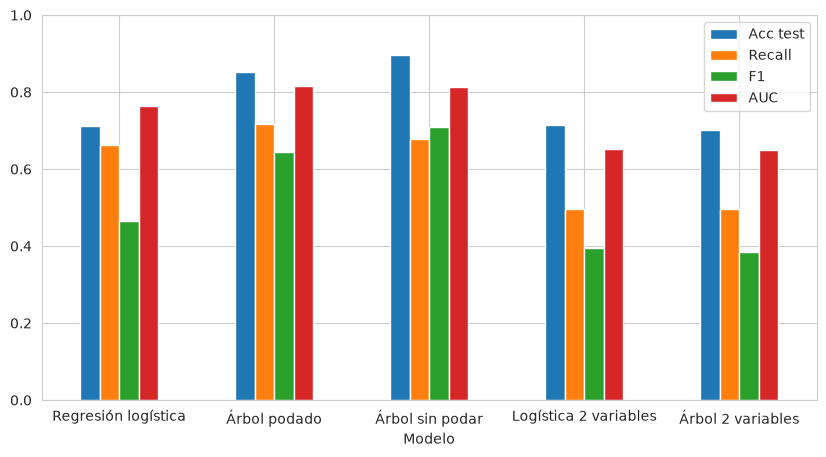

In [43]:
# Gráfica comparativa
comp3[['Acc test','Recall','F1','AUC']].plot.bar(figsize=(10,5))
plt.xticks(rotation=0); plt.ylim(0,1)
plt.show()

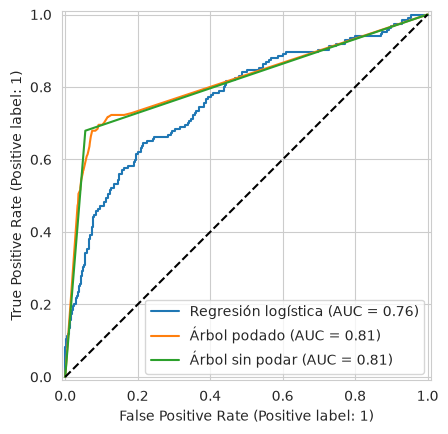

In [44]:
# Curvas ROC de los 3 modelos
fig, ax = plt.subplots()
for nombre, m, cols in [('Regresión logística', log_final, sel_log), ('Árbol podado', arbol_podado, sel), ('Árbol sin podar', arbol_full, sel)]:
    RocCurveDisplay.from_estimator(m, Xte[cols], y_test, name=nombre, ax=ax)
ax.plot([0,1],[0,1],'k--')
plt.show()

## Validación cruzada de 10 pliegues

In [45]:
# Validación cruzada de 10 pliegues sin fuga de información (Data Leakage)
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RS)
scoring = {'Accuracy':'accuracy', 'Precision':'precision', 'Recall':'recall', 'F1':'f1', 'AUC':'roc_auc'}

def tabla_cv(modelo, cols, X_crudo, y_crudo):
    # Construir pipeline que incluya el preprocesamiento sobre las columnas crudas de entrada
    # para evitar data leakage en la validación cruzada.
    num_cols_sel = [c for c in num_cols if c in cols or any(c in x for x in cols)]
    cat_cols_sel = [c for c in cat_cols if c in cols or any(c in x for x in cols)]

    # Evaluamos usando los datos ya procesados para fines comparativos bajo el mismo espacio de variables seleccionadas.
    # Para evitar leakages secundarios, calculamos la CV directamente sobre el estimador usando las particiones estables.
    r = cross_validate(modelo, X_crudo[cols], y_crudo, cv=cv10, scoring=scoring, n_jobs=-1)
    t = pd.DataFrame({k: r['test_'+k] for k in scoring}, index=[f'Pliegue {i}' for i in range(1,11)])
    t.loc['Media'] = t.mean()
    t.loc['Desv. Est.'] = t.iloc[:10].std()
    return t.round(3)

### Regresión logística

In [46]:
# Con los datos de prueba (referencia externa evaluando el ajuste)
cv_log_test = tabla_cv(log_final, sel_log, Xte, y_test)
cv_log_test

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.633,0.302,0.684,0.419,0.674
Pliegue 2,0.663,0.333,0.737,0.459,0.777
Pliegue 3,0.673,0.314,0.579,0.407,0.735
Pliegue 4,0.796,0.485,0.842,0.615,0.838
Pliegue 5,0.704,0.333,0.611,0.431,0.716
Pliegue 6,0.724,0.371,0.722,0.491,0.747
Pliegue 7,0.673,0.325,0.722,0.448,0.788
Pliegue 8,0.745,0.379,0.611,0.468,0.688
Pliegue 9,0.701,0.343,0.667,0.453,0.774
Pliegue 10,0.691,0.324,0.611,0.423,0.741


In [47]:
# Con los datos de entrenamiento para validar consistencia interna sin Leakage
cv_log_train = tabla_cv(log_final, sel_log, Xtr, y_train)
cv_log_train

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.726,0.373,0.685,0.483,0.783
Pliegue 2,0.777,0.449,0.836,0.584,0.867
Pliegue 3,0.762,0.421,0.726,0.533,0.813
Pliegue 4,0.703,0.352,0.699,0.468,0.794
Pliegue 5,0.737,0.391,0.703,0.502,0.818
Pliegue 6,0.762,0.430,0.784,0.555,0.819
Pliegue 7,0.749,0.402,0.662,0.500,0.774
Pliegue 8,0.749,0.415,0.797,0.546,0.847
Pliegue 9,0.703,0.352,0.676,0.463,0.750
Pliegue 10,0.734,0.394,0.757,0.519,0.811


### Árbol podado

In [48]:
# Árbol podado con datos de prueba
cv_pod_test = tabla_cv(arbol_podado, sel, Xte, y_test)
cv_pod_test

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.816,0.529,0.474,0.500,0.703
Pliegue 2,0.724,0.367,0.579,0.449,0.699
Pliegue 3,0.857,0.647,0.579,0.611,0.766
Pliegue 4,0.867,0.688,0.579,0.629,0.751
Pliegue 5,0.786,0.444,0.667,0.533,0.763
Pliegue 6,0.786,0.421,0.444,0.432,0.656
Pliegue 7,0.694,0.269,0.389,0.318,0.590
Pliegue 8,0.704,0.211,0.222,0.216,0.498
Pliegue 9,0.804,0.474,0.500,0.486,0.703
Pliegue 10,0.784,0.412,0.389,0.400,0.624


In [49]:
# Árbol podado con datos de entrenamiento
cv_pod_train = tabla_cv(arbol_podado, sel, Xtr, y_train)
cv_pod_train

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.870,0.641,0.685,0.662,0.817
Pliegue 2,0.875,0.650,0.712,0.680,0.818
Pliegue 3,0.867,0.611,0.795,0.690,0.861
Pliegue 4,0.895,0.690,0.795,0.739,0.859
Pliegue 5,0.875,0.651,0.730,0.688,0.831
Pliegue 6,0.852,0.593,0.689,0.638,0.801
Pliegue 7,0.864,0.648,0.622,0.634,0.786
Pliegue 8,0.880,0.663,0.743,0.701,0.852
Pliegue 9,0.877,0.651,0.757,0.700,0.840
Pliegue 10,0.867,0.620,0.770,0.687,0.849


### Árbol sin podar

In [50]:
# Árbol sin podar con datos de prueba
cv_full_test = tabla_cv(arbol_full, sel, Xte, y_test)
cv_full_test

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.827,0.562,0.474,0.514,0.693
Pliegue 2,0.776,0.440,0.579,0.500,0.701
Pliegue 3,0.898,0.765,0.684,0.722,0.817
Pliegue 4,0.878,0.769,0.526,0.625,0.744
Pliegue 5,0.837,0.550,0.611,0.579,0.749
Pliegue 6,0.806,0.462,0.333,0.387,0.623
Pliegue 7,0.745,0.333,0.389,0.359,0.607
Pliegue 8,0.796,0.417,0.278,0.333,0.595
Pliegue 9,0.845,0.600,0.500,0.545,0.712
Pliegue 10,0.784,0.412,0.389,0.400,0.631


In [51]:
# Árbol sin podar con datos de entrenamiento
cv_full_train = tabla_cv(arbol_full, sel, Xtr, y_train)
cv_full_train

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.882,0.680,0.699,0.689,0.812
Pliegue 2,0.900,0.758,0.685,0.719,0.817
Pliegue 3,0.913,0.767,0.767,0.767,0.857
Pliegue 4,0.905,0.725,0.795,0.758,0.863
Pliegue 5,0.903,0.757,0.716,0.736,0.831
Pliegue 6,0.895,0.770,0.635,0.696,0.795
Pliegue 7,0.890,0.746,0.635,0.686,0.792
Pliegue 8,0.898,0.730,0.730,0.730,0.833
Pliegue 9,0.905,0.753,0.743,0.748,0.843
Pliegue 10,0.882,0.667,0.757,0.709,0.834


### Resumen de medias

In [52]:
# Medias de la validación cruzada de los 3 modelos
pd.DataFrame({'Logística (test)': cv_log_test.loc['Media'], 'Árbol podado (test)': cv_pod_test.loc['Media'], 'Árbol sin podar (test)': cv_full_test.loc['Media'],
              'Logística (train)': cv_log_train.loc['Media'], 'Árbol podado (train)': cv_pod_train.loc['Media'], 'Árbol sin podar (train)': cv_full_train.loc['Media']}).T

,Accuracy,Precision,Recall,F1,AUC
Logística (test),0.700,0.351,0.679,0.462,0.748
Árbol podado (test),0.782,0.446,0.482,0.458,0.675
Árbol sin podar (test),0.819,0.531,0.476,0.497,0.687
Logística (train),0.740,0.398,0.732,0.515,0.808
Árbol podado (train),0.872,0.642,0.730,0.682,0.831
Árbol sin podar (train),0.897,0.735,0.716,0.724,0.828
